###

<h1 style="text-align: center;">
Privacy-Preserving Risk-Based Authentication Using Homomorphic Encryption
</h1>


Account fraud is one of the most common security threats and can involve services such as financial accounts, educational platform accounts, professional accounts, and healthcare platforms that contain sensitive data. Risk-Based Authentication (RBA) systems are usually used to detect suspicious logins, and if the risk score is high, reauthentication or MFA is usually required. However, RBA models are based on factors such as previous login history, location, IP address, and device fingerprints. Therefore, the following notebook explores whether protecting such sensitive data is possible by performing inference on fully homomorphically encrypted data and what the trade-offs are between FHE and plaintext.

**Pipeline**

<div style="text-align: center;">
    <img src="Images/ML_pipeline.jpg" alt="ML pipeline" width="900">
</div>

## I. Environment Setup and Library Imports

In [1]:
import json
import time
import warnings
from pathlib import Path
from IPython.display import display

import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    make_scorer,
    recall_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
plt.rcParams['figure.dpi'] = 110

In [2]:
# Paths for the dataset 
DATASET_CSV = Path('../datasets/rba-dataset.csv')

# Reproducibility
SEED = 42
np.random.seed(SEED)

# Decision threshold
DECISION_THRESHOLD = 0.25

## II. Dataset Analysis

The RBA dataset contains synthesised login-attempt records from a Norwegian single sign on service.  Features can be classified across four categories:
 - network identity (IP, country, ASN)
 - device fingerprint (device type, OS, browser)
 - temporal context (timestamp)
 - authentication outcome


### 1. Load Dataset

Because this notebook is run inside a container with limited memory capacity (24 GB), it is not possible to load all features from the beginning.
We chose to discard the following features:
- User Agent String
- Round-Trip Time (96% missing)

In [3]:
# Load dataset
LOAD_COLS = [
    'Login Timestamp', 'User ID',
    'Country', 'Region', 'City',
    'Browser Name and Version', 'OS Name and Version', 'Device Type',
    'ASN', 'IP Address', 'Is Attack IP', 'Login Successful', 'Is Account Takeover',
]

NROWS = None
df_raw = pd.read_csv(DATASET_CSV, nrows=NROWS, low_memory=False, usecols=LOAD_COLS)
df_raw.info() 


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31269264 entries, 0 to 31269263
Data columns (total 13 columns):
 #   Column                    Dtype 
---  ------                    ----- 
 0   Login Timestamp           object
 1   User ID                   int64 
 2   IP Address                object
 3   Country                   object
 4   Region                    object
 5   City                      object
 6   ASN                       int64 
 7   Browser Name and Version  object
 8   OS Name and Version       object
 9   Device Type               object
 10  Login Successful          bool  
 11  Is Attack IP              bool  
 12  Is Account Takeover       bool  
dtypes: bool(3), int64(2), object(8)
memory usage: 2.4+ GB


In [4]:
# Transform all columns with 'object' dtype to 'category' to save memory

print(f'Loaded {len(df_raw):,} rows x {df_raw.shape[1]} columns')
print(f'Memory (raw strings): {df_raw.memory_usage(deep=True).sum() / 1e6:,.0f} MB')

for col in ['Country', 'Region', 'City', 'Browser Name and Version', 'OS Name and Version', 'Device Type', 'IP Address']:
    df_raw[col] = df_raw[col].astype('category')

print(f'Memory (after category): {df_raw.memory_usage(deep=True).sum() / 1e6:,.0f} MB')
df_raw.head(5)

Loaded 31,269,264 rows x 13 columns
Memory (raw strings): 17,640 MB
Memory (after category): 4,013 MB


,Login Timestamp,User ID,IP Address,Country,Region,City,ASN,Browser Name and Version,OS Name and Version,Device Type,Login Successful,Is Attack IP,Is Account Takeover
0,2020-02-03 12:43:30.772,-4324475583306591935,10.0.65.171,NO,-,-,29695,Firefox 20.0.0.1618,iOS 13.4,mobile,False,False,False
1,2020-02-03 12:43:43.549,-4324475583306591935,194.87.207.6,AU,-,-,60117,Chrome Mobile 46.0.2490,Android 4.1,mobile,False,False,False
2,2020-02-03 12:43:55.873,-3284137479262433373,81.167.144.58,NO,Vestland,Urangsvag,29695,Android 2.3.3.2672,iOS 7.1,mobile,True,False,False
3,2020-02-03 12:43:56.180,-4324475583306591935,170.39.78.152,US,-,-,393398,Chrome Mobile WebView 85.0.4183,Android 4.1,mobile,False,False,False
4,2020-02-03 12:43:59.396,-4618854071942621186,10.0.0.47,US,Virginia,Ashburn,398986,Chrome Mobile WebView 85.0.4183,Android 2.2,mobile,False,True,False


### 2. Missing Values

For most features, all values are available. The exceptions are:

- Region: 0.15% missing values
- City: 0.03% missing values

In [5]:
info = pd.DataFrame({
    'dtype':      df_raw.dtypes.astype(str),
    'non_null':   df_raw.notnull().sum(),
    'null_%':     (df_raw.isnull().mean() * 100).round(2),
    'nunique':    df_raw.nunique(),
})
print('Missing Values:')
print(info.to_string())

Missing Values:
                             dtype  non_null  null_%   nunique
Login Timestamp             object  31269264    0.00  31269085
User ID                      int64  31269264    0.00   4304857
IP Address                category  31269264    0.00   3512330
Country                   category  31269264    0.00       229
Region                    category  31221855    0.15      2638
City                      category  31260674    0.03     38885
ASN                          int64  31269264    0.00     12955
Browser Name and Version  category  31269264    0.00      4549
OS Name and Version       category  31269264    0.00       653
Device Type               category  31267738    0.00         5
Login Successful              bool  31269264    0.00         2
Is Attack IP                  bool  31269264    0.00         2
Is Account Takeover           bool  31269264    0.00         2


### 3. Class balance

The RBA dataset is highly imbalanced.

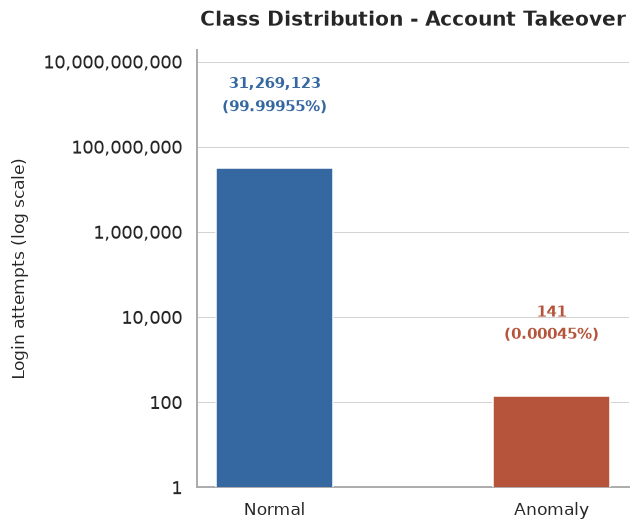

Total logins : 31,269,264
Unique users : 4,304,857


In [6]:
# Class balance
from IPython.display import display

n_total = len(df_raw)
n_tak = df_raw["Is Account Takeover"].isin([True, "True"]).sum()
n_users = df_raw["User ID"].nunique()

LABEL_COL = "Is Account Takeover"
n_pos = n_tak
n_neg = n_total - n_tak

counts = [n_neg, n_pos]
labels = ["Normal", "Anomaly"]
palette = ["#3567A0", "#B5543A"]   

fig, ax = plt.subplots(figsize=(6, 5))

bars = ax.bar(
    labels, counts,
    color=palette, width=0.42,
    edgecolor="white", linewidth=1.0,
    zorder=3,
)

ax.set_yscale("log")
ax.set_ylim(bottom=1, top=max(counts) * 600)

ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda v, _: f"{int(v):,}" if v >= 1 else "")
)
ax.set_ylabel("Login attempts (log scale)", labelpad=10, fontsize=11)
ax.set_title("Class Distribution - Account Takeover", fontweight="bold", fontsize=13, pad=16)
ax.tick_params(axis="x", labelsize=11)

# Horizontal grid behind bars
ax.set_axisbelow(True)
ax.yaxis.grid(True, which="both", linestyle="-", linewidth=0.55, color="#cccccc")
ax.xaxis.grid(False)

# Clean up spines
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#aaaaaa")

# Labels: count + share, well clear of the bar top
for bar, val, color in zip(bars, counts, palette):
    pct = val / n_total * 100
    x   = bar.get_x() + bar.get_width() / 2
    ax.text(
        x, val * 15,
        f"{val:,}\n({pct:.5f}%)",
        ha="center", va="bottom",
        fontsize=9.5, fontweight="bold",
        color=color, linespacing=1.6,
    )

plt.tight_layout()
plt.show()

# Summary table
print(f"Total logins : {n_total:,}")
print(f"Unique users : {n_users:,}")

### 4. Temporal Distribution of Attacks

Because the memory constraints caused multiple issues, the temporal distribution of attacks was analyzed in order to decide which part of the dataset could be removed optimally.

The goal was to preserve all positive samples, since there were only a few of them anyway. It was observed that after 2020-11, there were no other samples classified as attacks. Therefore, all samples later than 2020-11 were removed.

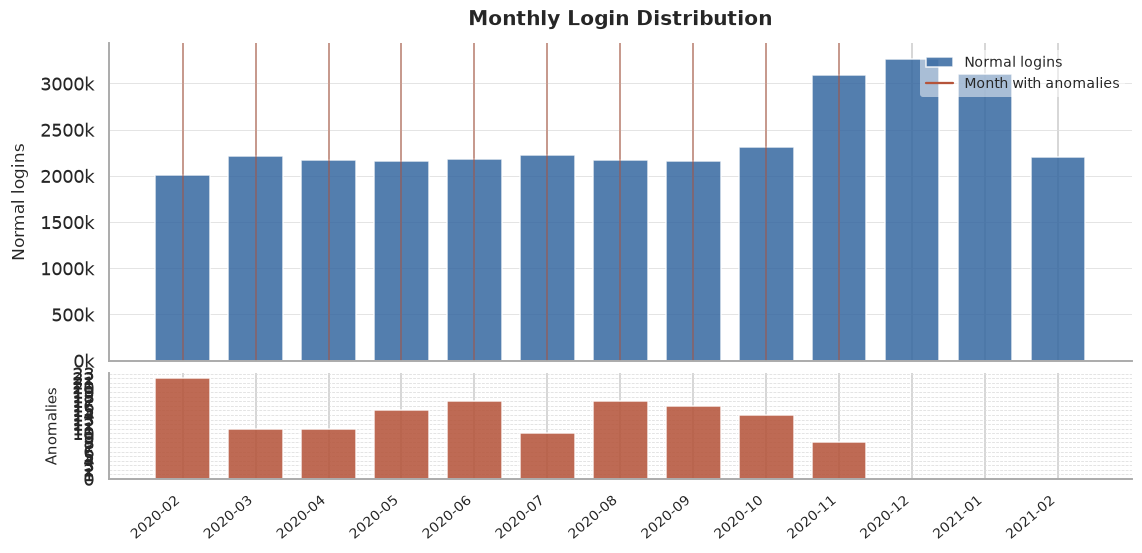

In [7]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

ts_all = pd.to_datetime(df_raw['Login Timestamp'], errors='coerce')
is_anomaly = df_raw['Is Account Takeover'].isin([True, 'True'])

monthly_normal = ts_all[~is_anomaly].dt.to_period('M').value_counts().sort_index()
monthly_anomaly = ts_all[ is_anomaly].dt.to_period('M').value_counts().sort_index()

all_months = monthly_normal.index.union(monthly_anomaly.index).sort_values()
normal_vals = monthly_normal.reindex(all_months, fill_value=0)
anomaly_vals = monthly_anomaly.reindex(all_months, fill_value=0)
x = np.arange(len(all_months))
xlabels = [str(m) for m in all_months]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

ax1.bar(x, normal_vals.values, color='#3567A0', alpha=0.85, width=0.75)
ax1.set_ylabel('Normal logins', fontsize=11, labelpad=8)
ax1.set_title('Monthly Login Distribution', fontweight='bold', fontsize=13, pad=12)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{int(v/1e3)}k'))
ax1.spines[['top', 'right']].set_visible(False)
ax1.spines[['left', 'bottom']].set_color('#aaaaaa')
ax1.set_axisbelow(True)
ax1.yaxis.grid(True, linestyle='-', linewidth=0.5, color='#dddddd')

for i, v in enumerate(anomaly_vals.values):
    if v > 0:
        ax1.axvline(i, color='#B5543A', alpha=0.5, linestyle='-', linewidth=1.2)

ax1.legend(handles=[
    Patch(facecolor='#3567A0', alpha=0.85, label='Normal logins'),
    Line2D([0], [0], color='#B5543A', linestyle='-', lw=1.5, label='Month with anomalies'),
], fontsize=9, framealpha=0.5, edgecolor='none')

ax2.bar(x, anomaly_vals.values, color='#B5543A', alpha=0.87, width=0.75)
ax2.set_ylabel('Anomalies', fontsize=10, labelpad=8)
ax2.spines[['top', 'right']].set_visible(False)
ax2.spines[['left', 'bottom']].set_color('#aaaaaa')
ax2.set_axisbelow(True)
ax2.yaxis.grid(True, linestyle='--', linewidth=0.5, color='#dddddd')
ax2.set_yticks(range(0, int(anomaly_vals.max()) + 2))
ax2.set_xticks(x)
ax2.set_xticklabels(xlabels, rotation=40, ha='right', fontsize=9)

fig.subplots_adjust(bottom=0.22, hspace=0.06)
plt.show()

In [8]:
# Trim dataset to rows up to end of 2020-11 (last month containing anomalies)
import gc

_ts = pd.to_datetime(df_raw['Login Timestamp'], errors='coerce')
before = len(df_raw)
df_raw = df_raw[_ts < '2020-12-01'].reset_index(drop=True)
del _ts
gc.collect()

after = len(df_raw)
print(f'Rows before cutoff:  {before:>12,}')
print(f'Rows after cutoff:   {after:>12,}')
print(f'Anomalies preserved: {df_raw["Is Account Takeover"].isin([True, "True"]).sum()}')

Rows before cutoff:    31,269,264
Rows after cutoff:     22,694,974
Anomalies preserved: 141


### 5. Geographic Characterisation


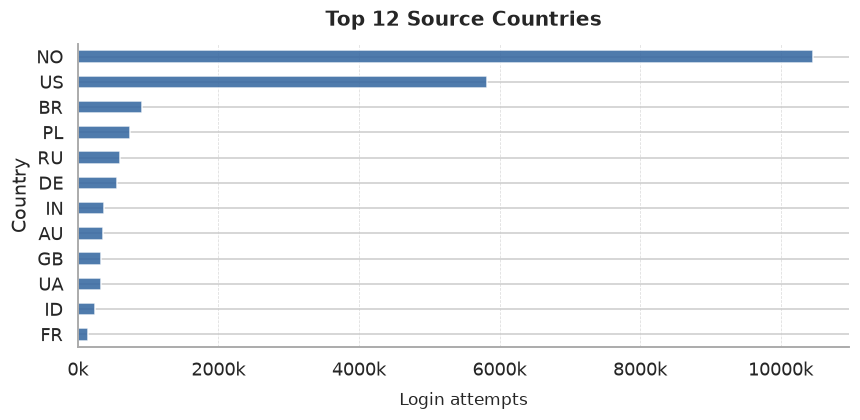

In [9]:
# Geographic characterisation
fig, ax = plt.subplots(figsize=(8, 4))

top_c = df_raw['Country'].value_counts().head(12).sort_values()
top_c.plot.barh(ax=ax, color='#3567A0', alpha=0.87)
ax.set_title('Top 12 Source Countries', fontweight='bold', fontsize=13, pad=12)
ax.set_xlabel('Login attempts', fontsize=11, labelpad=8)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{int(v/1e3)}k'))
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#aaaaaa')
ax.set_axisbelow(True)
ax.xaxis.grid(True, linestyle='--', linewidth=0.5, color='#dddddd')
plt.tight_layout()
plt.show()

### 6. Login Frequncy per user


Login frequency per user:
count    3536462.00
mean           6.42
std         4957.53
min            1.00
25%            1.00
50%            2.00
75%            4.00
max      9322666.00
Users with >=2 logins : 2,114,776  (59.8%)
Users with >=5 logins : 782,946  (22.1%)
Users with >20 logins : 59,154  (not shown in chart - long tail)


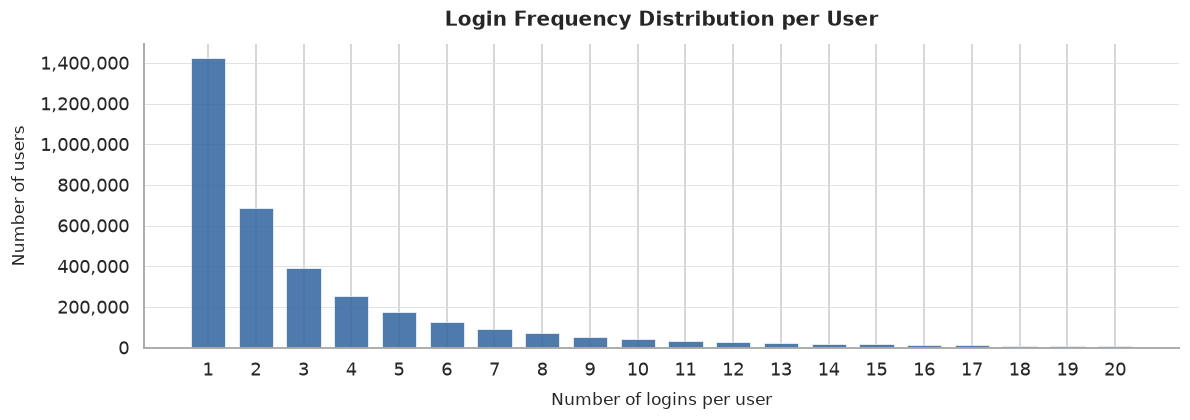

In [10]:
# Login frequency per user
lpu = df_raw.groupby('User ID').size()

print('Login frequency per user:')
print(lpu.describe().round(2).to_string())
print(f'Users with >=2 logins : {(lpu >= 2).sum():,}  ({(lpu >= 2).mean()*100:.1f}%)')
print(f'Users with >=5 logins : {(lpu >= 5).sum():,}  ({(lpu >= 5).mean()*100:.1f}%)')
print(f'Users with >20 logins : {(lpu > 20).sum():,}  (not shown in chart - long tail)')

CAP = 20
vc = lpu.value_counts().sort_index()
vc_show = vc[vc.index <= CAP]

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(vc_show.index, vc_show.values, color='#3567A0', alpha=0.87, width=0.72, edgecolor='white', linewidth=0.5)
ax.set_xlabel('Number of logins per user', fontsize=11, labelpad=8)
ax.set_ylabel('Number of users', fontsize=11, labelpad=8)
ax.set_title('Login Frequency Distribution per User', fontweight='bold', fontsize=13, pad=12)
ax.set_xticks(range(1, CAP + 1))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{int(v):,}'))
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#aaaaaa')
ax.set_axisbelow(True)
ax.yaxis.grid(True, linestyle='-', linewidth=0.55, color='#dddddd')
plt.tight_layout()
plt.show()

## II. Feature Engineering 

### 1. Consecutive Login Pairs

A single login event carries no temporal context. Impossible travel can only be detected by comparing a login event against the immediately preceding login of the same user.

This requires computing pair-level delta features. The dataset is sorted globally by timestamp, meaning all events are in chronological order across all users, but not necessarily per user. Therefore, to create the pairs more easily, the dataset is first sorted by user and then by timestamp.

The first login event of each user is discarded because no previous login is available for comparison.


| Feature | Type | Description |
|---------|------|-------------|
| `distance_km` | continuous | Distance between login countries (haversine on centroids) |
| `speed_kmh` | continuous | Implied travel speed |
| `time_delta_h` | continuous | Elapsed hours since previous login |
| `same_country` | binary | Country unchanged from previous login (1 = same) |
| `same_city` | binary | City unchanged |
| `same_browser` | binary | Browser + version unchanged |
| `same_os` | binary | OS + version unchanged |
| `same_device` | binary | Device type unchanged |
| `hour_of_day` | ordinal | Hour of login (0-23) |
| `is_weekend` | binary | Weekend login flag |


Geographic distance is approximated through country centroids. 

In [11]:
# Country centroids + vectorised haversine
COUNTRY_CENTROIDS = {
    'AF':(33.93,67.71),'AL':(41.15,20.17),'DZ':(28.03,1.66),
    'AO':(-11.2,17.87),'AR':(-38.42,-63.62),'AT':(47.52,14.55),
    'AU':(-25.27,133.78),'AZ':(40.14,47.58),'BA':(43.92,17.67),
    'BD':(23.68,90.36),'BE':(50.5,4.47),'BG':(42.73,25.49),
    'BO':(-16.29,-63.59),'BR':(-14.24,-51.93),'BY':(53.71,28.0),
    'CA':(56.13,-106.35),'CH':(46.82,8.23),'CL':(-35.68,-71.54),
    'CN':(35.86,104.2),'CO':(4.57,-74.3),'CZ':(49.82,15.47),
    'DE':(51.17,10.45),'DK':(56.26,9.5),'DO':(18.74,-70.16),
    'EC':(-1.83,-78.18),'EE':(58.6,25.01),'EG':(26.82,30.8),
    'ES':(40.46,-3.75),'ET':(9.15,40.49),'FI':(61.92,25.75),
    'FR':(46.23,2.21),'GB':(55.38,-3.44),'GE':(42.32,43.36),
    'GH':(7.95,-1.02),'GR':(39.07,21.82),'HK':(22.4,114.11),
    'HR':(45.1,16.45),'HU':(47.16,19.5),'ID':(-0.79,113.92),
    'IE':(53.41,-8.24),'IL':(31.05,34.85),'IN':(20.59,78.96),
    'IQ':(33.22,43.68),'IR':(32.43,53.69),'IS':(64.96,-19.02),
    'IT':(41.87,12.57),'JP':(36.2,138.25),'KE':(-0.02,37.91),
    'KR':(35.91,127.77),'KZ':(48.02,66.92),'LT':(55.17,23.88),
    'LV':(56.88,24.6),'MA':(31.79,-7.09),'MD':(47.41,28.37),
    'MX':(23.63,-102.55),'MY':(4.21,101.98),'NG':(9.08,8.68),
    'NL':(52.13,5.29),'NO':(60.47,8.47),'NZ':(-40.9,174.89),
    'PE':(-9.19,-75.02),'PH':(12.88,121.77),'PK':(30.38,69.35),
    'PL':(51.92,19.15),'PT':(39.4,-8.22),'RO':(45.94,24.97),
    'RS':(44.02,21.01),'RU':(61.52,105.32),'SA':(23.89,45.08),
    'SE':(60.13,18.64),'SG':(1.35,103.82),'SK':(48.67,19.7),
    'TH':(15.87,100.99),'TN':(33.89,9.54),'TR':(38.96,35.24),
    'TW':(23.7,121.0),'UA':(48.38,31.17),'US':(37.09,-95.71),
    'UZ':(41.38,64.59),'VN':(14.06,108.28),'ZA':(-30.56,22.94),
}
_LAT = {k: v[0] for k, v in COUNTRY_CENTROIDS.items()}
_LON = {k: v[1] for k, v in COUNTRY_CENTROIDS.items()}


In [12]:
def haversine_vectorised(lat1, lon1, lat2, lon2):
    R = 6371.0
    dlat = np.radians(lat2 - lat1)
    dlon = np.radians(lon2 - lon1)
    a = (np.sin(dlat / 2) ** 2 + np.cos(np.radians(lat1)) * np.cos(np.radians(lat2)) * np.sin(dlon / 2) ** 2)
    return 2.0 * R * np.arcsin(np.sqrt(np.clip(a, 0.0, 1.0)))


In [13]:
# New features added
FEATURE_COLS = [
    'distance_km', 'speed_kmh', 'time_delta_h',
    'same_country', 'same_region', 'same_city',
    'same_browser', 'same_os', 'same_device', 'same_asn',
    'hour_of_day', 'is_weekend',
    'is_attack_ip', 'prev_is_attack_ip', 'prev_login_failed',
    'same_ip', 'same_ip_prefix',
    'is_first_login',
]

MAX_SPEED_KMH = 50_000

def engineer_pair_features(df: pd.DataFrame, label_col: str) -> pd.DataFrame:
    df = df.copy()

    # the login timestamp is converted from object to pandas date-time type
    df['Login Timestamp'] = pd.to_datetime(df['Login Timestamp'], errors='coerce')

    # transform the target column from false/true to 0/1
    df[label_col] = df[label_col].isin([True, 'True']).astype(np.int8)

    # rows are sorted first by user and then chronologically
    df = df.sort_values(['User ID', 'Login Timestamp']).reset_index(drop=True)

    # group the logins by user and then save for each login the previous state for each feature
    grp = df.groupby('User ID', sort=False)
    for col in ['Login Timestamp', 'Country', 'Region', 'City', 'Browser Name and Version', 'OS Name and Version', 'Device Type',
                'ASN', 'IP Address', 'Is Attack IP', 'Login Successful']:
        df[f'_p_{col}'] = grp[col].shift(1)

    # if a login is the first one
    first_login_mask = df['_p_Login Timestamp'].isna()
    df['is_first_login'] = first_login_mask.astype(np.int8)

    # replace the missing values of previous logins with the values of the current
    df['_p_Login Timestamp'] = df['_p_Login Timestamp'].fillna(df['Login Timestamp'])
    for col in ['Country', 'Region', 'City', 'Browser Name and Version', 'OS Name and Version', 'Device Type', 'ASN', 'IP Address']:
        df[f'_p_{col}'] = df[f'_p_{col}'].fillna(df[col])
        
    df['_p_Is Attack IP']  = df['_p_Is Attack IP'].fillna(False)
    df['_p_Login Successful'] = df['_p_Login Successful'].fillna(True)

    # temporal new features
    elapsed_s = (df['Login Timestamp'] - df['_p_Login Timestamp']
                 ).dt.total_seconds().clip(lower=0)
    df['time_delta_h'] = elapsed_s / 3600.0
    df['hour_of_day'] = df['Login Timestamp'].dt.hour
    df['is_weekend'] = (df['Login Timestamp'].dt.dayofweek >= 5).astype(np.int8)

    # location new features
    df['same_country'] = (df['Country'] == df['_p_Country']).astype(np.int8)
    df['same_region'] = (df['Region']  == df['_p_Region']).astype(np.int8)
    df['same_city'] = (df['City'] == df['_p_City']).astype(np.int8)

    # device fingerprint new features
    df['same_browser'] = (
        df['Browser Name and Version'] == df['_p_Browser Name and Version']
    ).astype(np.int8)
    df['same_os'] = (
        df['OS Name and Version'] == df['_p_OS Name and Version']
    ).astype(np.int8)
    df['same_device'] = (
        df['Device Type'] == df['_p_Device Type']
    ).astype(np.int8)
    df['same_asn'] = (df['ASN'] == df['_p_ASN']).astype(np.int8)

    df['is_attack_ip'] = df['Is Attack IP'].isin([True, 'True']).astype(np.int8)
    df['prev_is_attack_ip'] = df['_p_Is Attack IP'].isin([True, 'True']).astype(np.int8)
    df['prev_login_failed'] = (~df['_p_Login Successful'].isin([True, 'True'])).astype(np.int8)

    ip_cur = df['IP Address'].astype(str)
    ip_prev = df['_p_IP Address'].astype(str)
    df['same_ip'] = (ip_cur == ip_prev).astype(np.int8)
    df['same_ip_prefix'] = (
        ip_cur.str.rsplit('.', n=1).str[0] == ip_prev.str.rsplit('.', n=1).str[0]
    ).astype(np.int8)

    # compute the distance between the center of current country to the previous
    lat_cur = df['Country'].map(_LAT).values.astype(float)
    lon_cur = df['Country'].map(_LON).values.astype(float)
    lat_prev = df['_p_Country'].map(_LAT).values.astype(float)
    lon_prev = df['_p_Country'].map(_LON).values.astype(float)

    dist = haversine_vectorised(lat_cur, lon_cur, lat_prev, lon_prev)
    df['distance_km'] = np.where(np.isnan(lat_cur) | np.isnan(lat_prev), 0.0, dist)
    df['speed_kmh'] = np.where(
        df['time_delta_h'] > 0,
        np.minimum(df['distance_km'] / df['time_delta_h'], MAX_SPEED_KMH),
        np.where(df['distance_km'] > 0, float(MAX_SPEED_KMH), 0.0),
    )

    return df.drop(columns=[c for c in df.columns if c.startswith('_p_')])

The new engineered features are added as extensions to the dataset:

In [14]:
import gc

df = engineer_pair_features(df_raw, LABEL_COL)
del df_raw
gc.collect()

n_pos = int((df[LABEL_COL] == 1).sum())
n_neg = int((df[LABEL_COL] == 0).sum())
n_tot = len(df)

print('\nFeature statistics:')
df.info()


Feature statistics:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22694974 entries, 0 to 22694973
Data columns (total 31 columns):
 #   Column                    Dtype         
---  ------                    -----         
 0   Login Timestamp           datetime64[ns]
 1   User ID                   int64         
 2   IP Address                category      
 3   Country                   category      
 4   Region                    category      
 5   City                      category      
 6   ASN                       int64         
 7   Browser Name and Version  category      
 8   OS Name and Version       category      
 9   Device Type               category      
 10  Login Successful          bool          
 11  Is Attack IP              bool          
 12  Is Account Takeover       int8          
 13  is_first_login            int8          
 14  time_delta_h              float64       
 15  hour_of_day               int32         
 16  is_weekend                int8 

findfont: Failed to find font weight semibold, now using 700.


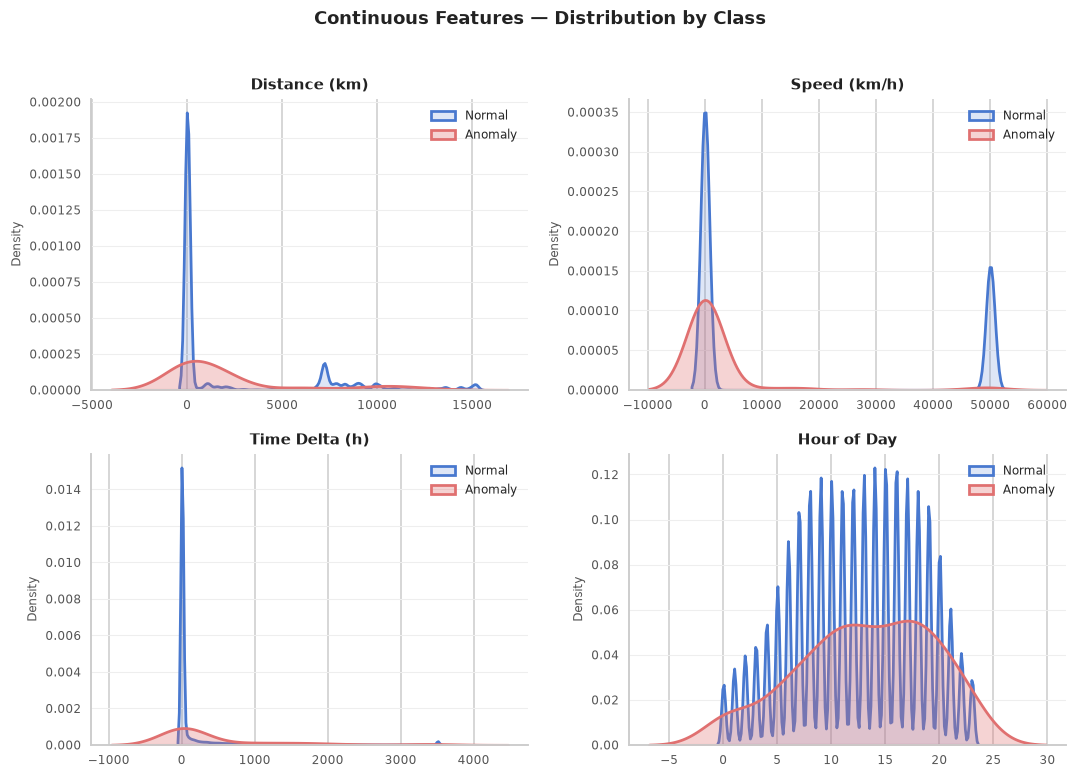

findfont: Failed to find font weight semibold, now using 700.


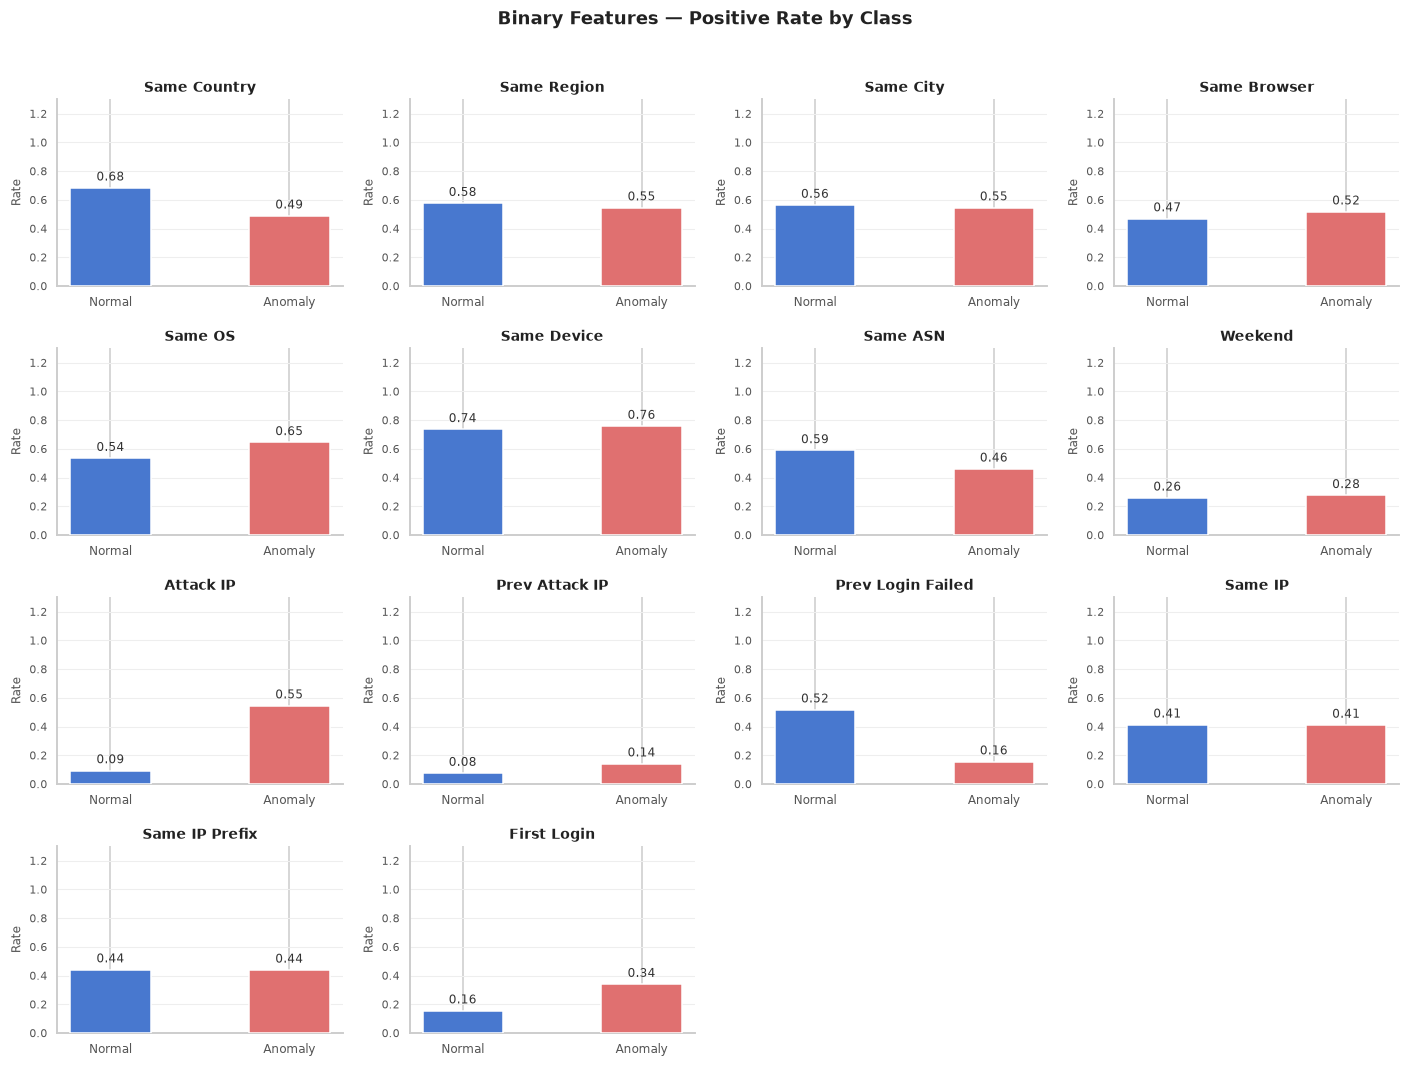

In [15]:
# Feature distributions: normal vs anomaly
df_pos = df[df[LABEL_COL] == 1]
df_neg = df[df[LABEL_COL] == 0]

CONTINUOUS_FEATS = ['distance_km', 'speed_kmh', 'time_delta_h', 'hour_of_day']
BINARY_FEATS = [f for f in FEATURE_COLS if f not in CONTINUOUS_FEATS]

C_NORM = '#4878CF'
C_ANOM = '#E07070'

FEAT_LABELS = {
    'distance_km':       'Distance (km)',
    'speed_kmh':         'Speed (km/h)',
    'time_delta_h':      'Time Delta (h)',
    'hour_of_day':       'Hour of Day',
    'same_country':      'Same Country',
    'same_region':       'Same Region',
    'same_city':         'Same City',
    'same_browser':      'Same Browser',
    'same_os':           'Same OS',
    'same_device':       'Same Device',
    'same_asn':          'Same ASN',
    'is_weekend':        'Weekend',
    'is_attack_ip':      'Attack IP',
    'prev_is_attack_ip': 'Prev Attack IP',
    'prev_login_failed': 'Prev Login Failed',
    'same_ip':           'Same IP',
    'same_ip_prefix':    'Same IP Prefix',
    'is_first_login':    'First Login',
}

def _strip(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#cccccc')
    ax.spines['bottom'].set_color('#cccccc')
    ax.tick_params(colors='#555555', length=3)
    ax.yaxis.grid(True, color='#eeeeee', linewidth=0.7, zorder=0)
    ax.set_axisbelow(True)

#  Continuous: 2 × 2 KDE grid 
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
fig.patch.set_facecolor('white')

for ax, feat in zip(axes.flat, CONTINUOUS_FEATS):
    cap = df[feat].quantile(0.99)
    vals_neg = df_neg[feat].clip(upper=cap)
    vals_pos = df_pos[feat].clip(upper=cap)
    sns.kdeplot(vals_neg, ax=ax, color=C_NORM, fill=True, alpha=0.18,
                linewidth=1.8, label='Normal')
    sns.kdeplot(vals_pos, ax=ax, color=C_ANOM, fill=True, alpha=0.30,
                linewidth=1.8, label='Anomaly')
    ax.set_title(FEAT_LABELS[feat], fontsize=10, fontweight='semibold',
                 color='#222222', pad=6)
    ax.set_xlabel('')
    ax.set_ylabel('Density', fontsize=8, color='#555555')
    ax.tick_params(labelsize=8)
    ax.legend(fontsize=8, frameon=False)
    _strip(ax)

fig.suptitle('Continuous Features — Distribution by Class',
             fontsize=12, fontweight='bold', color='#222222', y=1.01)
plt.tight_layout()
plt.show()

#  Binary: 4 × 4 bar grid 
N_COLS = 4
N_ROWS = (len(BINARY_FEATS) + N_COLS - 1) // N_COLS
fig, axes = plt.subplots(N_ROWS, N_COLS, figsize=(13, N_ROWS * 2.4))
fig.patch.set_facecolor('white')

for i, feat in enumerate(BINARY_FEATS):
    ax = axes.flat[i]
    norm_rate = df_neg[feat].mean()
    anom_rate = df_pos[feat].mean()
    bars = ax.bar(['Normal', 'Anomaly'], [norm_rate, anom_rate],
                  color=[C_NORM, C_ANOM], width=0.45, zorder=3)
    for bar, v in zip(bars, [norm_rate, anom_rate]):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.03,
                f'{v:.2f}', ha='center', va='bottom',
                fontsize=8, color='#333333')
    ax.set_title(FEAT_LABELS.get(feat, feat), fontsize=9,
                 fontweight='semibold', color='#222222', pad=5)
    ax.set_ylim(0, 1.30)
    ax.set_ylabel('Rate', fontsize=8, color='#555555')
    ax.tick_params(axis='x', labelsize=8, colors='#444444')
    ax.tick_params(axis='y', labelsize=7)
    _strip(ax)

for j in range(len(BINARY_FEATS), len(axes.flat)):
    axes.flat[j].set_visible(False)

fig.suptitle('Binary Features — Positive Rate by Class', fontsize=12, fontweight='bold', color='#222222', y=1.01)
plt.tight_layout()
plt.show()

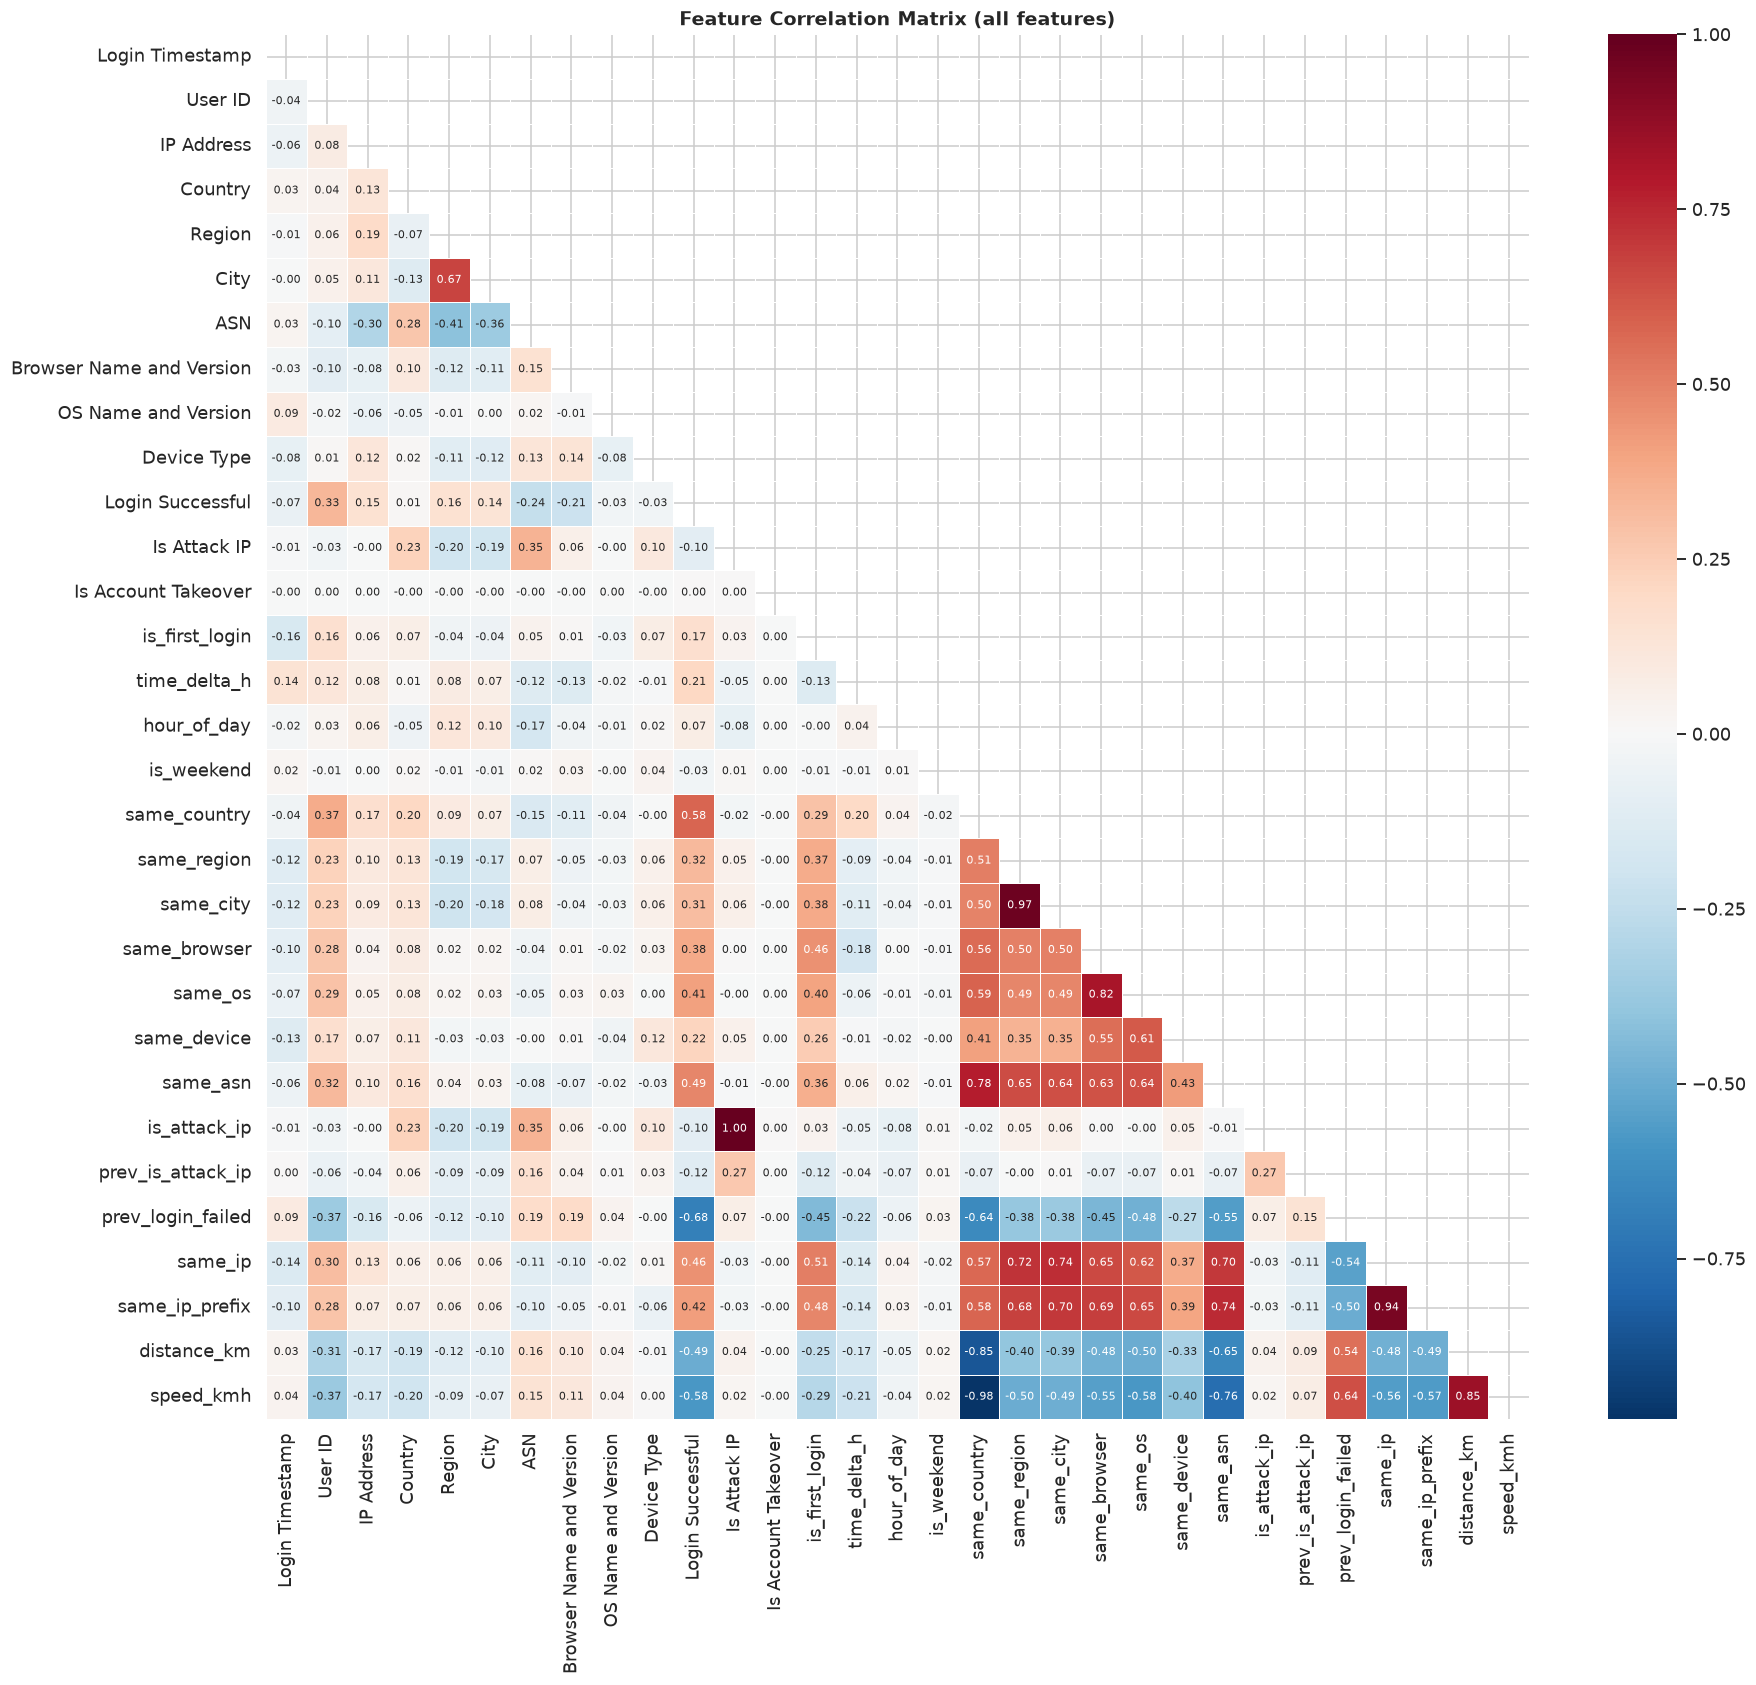

In [16]:
# Correlation analysis - all features present in the dataframe

df_corr = pd.DataFrame(index=df.index)
for col in df.columns:
    s = df[col]
    if hasattr(s, 'cat'):
        df_corr[col] = s.cat.codes         
    elif s.dtype == bool or str(s.dtype) == 'object':
        df_corr[col] = s.astype(np.int8)
    else:
        df_corr[col] = s

corr = df_corr.corr()
n = len(corr)
fig, ax = plt.subplots(figsize=(max(9, n * 0.55), max(7, n * 0.50)))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax, linewidths=0.4, annot_kws={'size': 7})
ax.set_title('Feature Correlation Matrix (all features)', fontweight='bold')
plt.tight_layout(); plt.show()

## III. Train/Test Split

The dataset is split in chronological order based on the timestamp. This avoids performing inference on a sample at a given time \(t_1\) using a model trained on samples from the future.

The split is performed as follows:

- 80% development set
  - 80% of the development set is used for training
  - 20% of the development set is used for validation
- 20% test set

In other words, the original dataset is divided into:

- 64% training set
- 16% validation set
- 20% test set

In [17]:
# 3. Train / Test split

SPLIT_RATIO  = 0.80

# Step 1: extract only needed columns, free the full df immediately
df_slim = df[FEATURE_COLS + [LABEL_COL, 'Login Timestamp']].copy()
del df
gc.collect()
print(f'df slimmed: {df_slim.memory_usage(deep=True).sum() / 1e6:.0f} MB')

# Step 2: sort on the slim frame
df_sorted = df_slim.sort_values('Login Timestamp').reset_index(drop=True)
del df_slim
gc.collect()

# Step 3: extract numpy arrays, free the sorted frame
split_idx = int(len(df_sorted) * SPLIT_RATIO)
X_all = df_sorted[FEATURE_COLS].values.astype(np.float32)
y_all = df_sorted[LABEL_COL].values.astype(np.int8)
del df_sorted
gc.collect()

# Step 4: temporal split
X_train_raw, X_test_raw = X_all[:split_idx], X_all[split_idx:]
y_train, y_test  = y_all[:split_idx], y_all[split_idx:]

del X_all, y_all
gc.collect()

print('Split Summary:')
print(f'{"":28} {"Train":>12} {"Test":>12}')
print(f'{"Samples":<28} {len(X_train_raw):>12,} {len(X_test_raw):>12,}')
print(f'{"Anomalies":<28} {int(y_train.sum()):>12,} {int(y_test.sum()):>12,}')
print(f'{"Positive rate":<28} {y_train.mean()*100:>11.4f}% {y_test.mean()*100:>11.4f}%')

df slimmed: 1157 MB
Split Summary:
                                    Train         Test
Samples                        18,155,979    4,538,995
Anomalies                             125           16
Positive rate                     0.0007%      0.0004%


In [18]:
# Hold out 20% of training as a validation set (stratified)

X_inner_raw, X_val_raw, y_inner, y_val = train_test_split(
    X_train_raw, y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=SEED,
)
del X_train_raw, y_train
gc.collect()

print('Validation Split')
print(f'{"":28} {"Inner Train":>14} {"Validation":>12}')
print(f'{"Samples":<28} {len(X_inner_raw):>14,} {len(X_val_raw):>12,}')
print(f'{"Anomalies":<28} {int(y_inner.sum()):>14,} {int(y_val.sum()):>12,}')
print(f'{"Positive rate":<28} {y_inner.mean()*100:>13.4f}% {y_val.mean()*100:>11.4f}%')

Validation Split
                                Inner Train   Validation
Samples                          14,524,783    3,631,196
Anomalies                               100           25
Positive rate                       0.0007%      0.0007%


## 4. Class Balancing Strategy

Less than 0.01% of the samples represent account takeover, meaning that the dataset is extremely imbalanced. If the dataset will be let in its current proportions, the model will learn to predict well only for normal logins, which would make this model useless. Therefore, a technique called SMOTE (Synthetic Minority Oversampling Technique) is applied. SMOTE uses existing samples from which interpolates their features to obtains new synthetic samples. It must be noted that is very important to apply it only on the training set, otherwise it will cause data leakage.



In [19]:
# 4. SMOTE oversampling — applied only to the inner training set (80% of training)

SMOTE_SUBSAMPLE = 500_000  

rng_s = np.random.default_rng(SEED)
pos_idx = np.where(y_inner == 1)[0]
neg_idx = np.where(y_inner == 0)[0]
n_neg_s = min(SMOTE_SUBSAMPLE - len(pos_idx), len(neg_idx))
sub_idx = np.concatenate([pos_idx, rng_s.choice(neg_idx, n_neg_s, replace=False)])
rng_s.shuffle(sub_idx)

X_pre_smote = X_inner_raw[sub_idx]
y_pre_smote = y_inner[sub_idx]

print(f'Pre-SMOTE subsample: {len(X_pre_smote):,} rows')
print(f'Positives:           {int(y_pre_smote.sum()):,}')
print(f'Negatives:           {int((y_pre_smote == 0).sum()):,}')

smote = SMOTE(random_state = SEED, k_neighbors = 5)
X_train_bal, y_train_fit = smote.fit_resample(X_pre_smote, y_pre_smote)
del X_pre_smote, y_pre_smote
import gc; gc.collect()

print(f'Post-SMOTE: {len(X_train_bal):,} rows')
print(f'Positives:  {int(y_train_fit.sum()):,}')
print(f'Negatives:  {int((y_train_fit == 0).sum()):,}')
print(f' Memory: {X_train_bal.nbytes / 1e6:.0f} MB')

Pre-SMOTE subsample: 500,000 rows
Positives:           100
Negatives:           499,900
Post-SMOTE: 999,800 rows
Positives:  499,900
Negatives:  499,900
 Memory: 72 MB


## V. Plaintext Model Training

To select the best hyperparameters, the model is trained on a subsample of 80,000 records and tested on the validation set to see how it performs. It uses grid search to try multiple hyperparameter combinations and chooses the best ones. After the hyperparameter tuning is completed, the model is trained again on the full training set and tested on the validation set. However, this result does not truly indicate the model's performance, as it was fine-tuned to perform well on the validation set.

As a consequence, the model will be tested at the end on a test set that was not seen or used during the development of the model.

In [ ]:
# V. StandardScaler + held-out grid search for XGBClassifier
from itertools import product as _product

scaler = StandardScaler()
scaler.fit(X_inner_raw)          # fit on real unbalanced inner train
X_train = scaler.transform(X_train_bal)
X_val   = scaler.transform(X_val_raw)
X_test  = scaler.transform(X_test_raw)

del X_train_bal
gc.collect()

# Random subsample for grid search (SMOTE output is already 50/50 balanced)
CV_SAMPLE = 999_800
rng_cv = np.random.default_rng(SEED)
cv_idx = rng_cv.choice(len(X_train), CV_SAMPLE, replace=False)
X_cv = X_train[cv_idx]
y_cv = y_train_fit[cv_idx]
print(f'CV subsample : {len(X_cv):,} rows  '
      f'(positives: {int(y_cv.sum())}, negatives: {int((y_cv==0).sum())})')

BASE_PARAMS = dict(
    subsample = 0.8,
    colsample_bytree = 0.8,
    gamma = 0.0,
    reg_lambda = 1.0,
    eval_metric = 'aucpr',
    random_state = SEED,
    n_jobs = -1,
    verbosity = 0,
)

PARAM_GRID = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.05, 0.1],
    'min_child_weight': [1, 5, 10, 20],
}

param_keys = list(PARAM_GRID.keys())
combos = list(_product(*PARAM_GRID.values()))
n_combos = len(combos)
print(f'\nHeld-out grid search: {n_combos} combinations scored by Recall on X_val ...')

best_recall = -1
best_combo = None
gs_results = []

t0 = time.time()
for i, values in enumerate(combos, 1):
    combo = dict(zip(param_keys, values))
    params = {**BASE_PARAMS, **combo}
    model = xgb.XGBClassifier(**params)
    model.fit(X_cv, y_cv)
    proba = model.predict_proba(X_val)[:, 1]
    preds = (proba >= DECISION_THRESHOLD).astype(np.int8)
    rec = recall_score(y_val, preds, pos_label=1, zero_division=0)
    gs_results.append({**combo, 'recall_val': rec})
    marker = '  <-- best' if rec > best_recall else ''
    print(f'  [{i:2}/{n_combos}] {combo}  recall={rec:.4f}{marker}')
    if rec > best_recall:
        best_recall = rec
        best_combo  = combo

print(f'\nDone in {time.time()-t0:.1f}s')
display(pd.DataFrame(
    [('Recall (val, best combo)', f'{best_recall:.4f}')],
    columns=['Metric', 'Value'],
).set_index('Metric'))
print(f'Best params : {best_combo}')

best_params = {**BASE_PARAMS, **best_combo}
del X_cv, model
gc.collect()

# Retrain on the full SMOTE-balanced inner training set with best params
print('\nTraining on full inner training set with best params ...')
pt_xgb = xgb.XGBClassifier(**best_params)
t0 = time.time()
pt_xgb.fit(X_train, y_train_fit)
print(f'Trained in {time.time()-t0:.1f}s')

## VI. Validation

The model is evaluated on a held-out validation set.
The metrics reported are:
- **Recall**: how mnay of the real anomalies are caught (primary metric for security)
- **ROC-AUC** 

In [ ]:
from sklearn.metrics import average_precision_score, f1_score, precision_score

print('Plaintext Validation Set:\n')

pt_val_proba = pt_xgb.predict_proba(X_val)[:, 1]
pt_val_preds = (pt_val_proba >= DECISION_THRESHOLD).astype(np.int8)

n_pos_val = int(y_val.sum())
val_recall = recall_score(y_val, pt_val_preds, pos_label=1, zero_division=0)
val_auc = roc_auc_score(y_val, pt_val_proba)
n_fp = int(((pt_val_preds == 1) & (y_val == 0)).sum())
n_fn = int(((pt_val_preds == 0) & (y_val == 1)).sum())

print(f'Validation set       : {len(y_val):,} samples  ({n_pos_val} real anomalies)')
print(f'Decision threshold   : {DECISION_THRESHOLD}\n')

display(pd.DataFrame(
    [
        ('Recall (anomaly)', f'{val_recall:.4f}'),
        ('ROC-AUC',          f'{val_auc:.4f}'),
        ('False Positives',  f'{n_fp:,}'),
        ('False Negatives',  f'{n_fn:,}'),
    ],
    columns=['Metric', 'Value'],
).set_index('Metric'))

# ROC and PR curves
fpr_v, tpr_v, _  = roc_curve(y_val, pt_val_proba)
fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(fpr_v, tpr_v, color='#3567A0', lw=2, label=f'ROC-AUC = {val_auc:.4f}')
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve - Validation', fontweight='bold')
ax.legend(fontsize=9)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(4, 4))
ConfusionMatrixDisplay(
    confusion_matrix(y_val, pt_val_preds),
    display_labels=['Normal', 'Anomaly'],
).plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title(f'Validation  (threshold = {DECISION_THRESHOLD})')
plt.tight_layout()
plt.show()

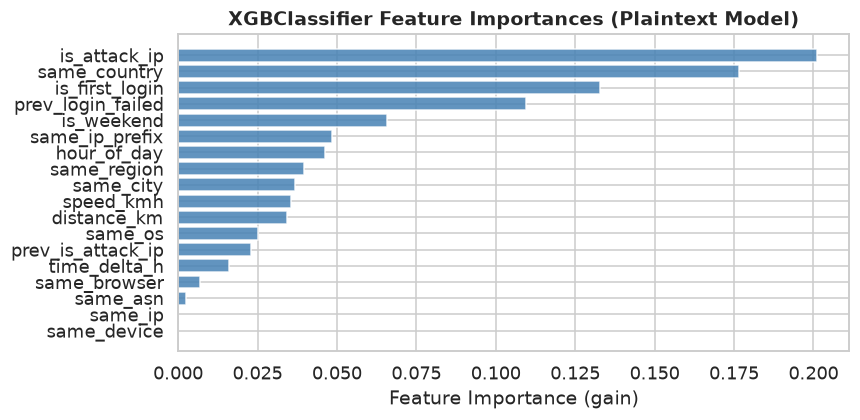

In [22]:
# Feature importance 
importances = pt_xgb.feature_importances_
sorted_idx  = np.argsort(importances)[::-1]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(
    [FEATURE_COLS[i] for i in sorted_idx[::-1]],
    importances[sorted_idx[::-1]],
    color='steelblue', alpha=0.85,
)
ax.set_xlabel('Feature Importance (gain)')
ax.set_title('XGBClassifier Feature Importances (Plaintext Model)', fontweight='bold')
plt.tight_layout(); plt.show()


## V. - B. Plaintext Retrain on Full Development Set

After the correct hyperparameters were chosen, the model is trained again on the full development set (training + validation), preparing it for the test set. Therefore, the scaler needs to be fitted again on the full development set. Additionally, SMOTE will also be performed on the full original development set.

In [ ]:
print('Re-training plaintext model on full training set:\n')

# Free intermediate scaled copies to make room for the raw concatenation
del X_val, X_train, y_train_fit
gc.collect()

X_full_raw = np.concatenate([X_inner_raw, X_val_raw])
y_full = np.concatenate([y_inner, y_val])
del X_inner_raw, X_val_raw, y_inner, y_val
gc.collect()
print(f'Full train raw : {len(X_full_raw):,} rows  (anomalies: {int(y_full.sum())})')

# SMOTE on the full training subsample
rng_r = np.random.default_rng(SEED)
pos_idx = np.where(y_full == 1)[0]
neg_idx = np.where(y_full == 0)[0]
n_neg_r = min(SMOTE_SUBSAMPLE - len(pos_idx), len(neg_idx))
sub_r = np.concatenate([pos_idx, rng_r.choice(neg_idx, n_neg_r, replace=False)])
rng_r.shuffle(sub_r)
X_pre_r = X_full_raw[sub_r]
y_pre_r = y_full[sub_r]

smote_r = SMOTE(random_state=SEED, k_neighbors=5)
X_full_bal, y_full_fit = smote_r.fit_resample(X_pre_r, y_pre_r)
del X_pre_r, y_pre_r
gc.collect()
print(f'Post-SMOTE: {len(X_full_bal):,} rows  (positives: {int(y_full_fit.sum())})')

# Refit scaler on full raw training distribution
scaler.fit(X_full_raw)
del X_full_raw
gc.collect()

X_train_final = scaler.transform(X_full_bal)
del X_full_bal
gc.collect()

# Rescale X_test with the updated scaler 
X_test = scaler.transform(X_test_raw)
del X_test_raw
gc.collect()

# Retrain plaintext model in-place
pt_xgb.fit(X_train_final, y_full_fit);
print('Retrained on full development set.')

## V. - C. FHE Model Training

The FHE model is trained on X_train_final, the same full training set used for the plaintext model training. We will not do any valdation and hyperparamter tuning on this model, as the same hyperparameters will be used as for the plaintext model.

In [24]:
from concrete.ml.sklearn import XGBClassifier as FHEXGBClassifier

FHE_SUBSAMPLE = 999_800

FHE_PARAMS = dict(
    n_bits = 6,
    n_estimators = 50,
    max_depth = 3,
    learning_rate = 0.05,
    min_child_weight = 1,
    gamma = 0.0,
    random_state = SEED,
    n_jobs = -1,
)

rng_fhe = np.random.default_rng(SEED)
fhe_idx = rng_fhe.choice(len(X_train_final), min(FHE_SUBSAMPLE, len(X_train_final)), replace=False)
X_fhe = X_train_final[fhe_idx]
y_fhe = y_full_fit[fhe_idx]

print(f'FHE training subsample : {len(X_fhe):,} rows')
print(f'Positives              : {int(y_fhe.sum())}')
print(f'Negatives              : {int((y_fhe == 0).sum())}')
print(f'Memory                 : {X_fhe.nbytes / 1e6:.0f} MB\n')

fhe_xgb = FHEXGBClassifier(**FHE_PARAMS)
t0 = time.time()
fhe_xgb.fit(X_fhe, y_fhe)
print(f'Fitted in {time.time()-t0:.1f}s')

rng_c = np.random.default_rng(SEED)
cal_idx = rng_c.choice(len(X_fhe), min(1_000, len(X_fhe)), replace=False)
t0 = time.time()
fhe_xgb.compile(X_fhe[cal_idx])
print(f'Circuit compiled in {time.time()-t0:.1f}s')

del X_train_final, X_fhe, y_fhe, y_full_fit
gc.collect()


FHE training subsample : 999,750 rows
  Positives            : 499875
  Negatives            : 499875
  Memory               : 72 MB

Training FHE XGBClassifier (n_bits=6, n_estimators=50, max_depth=3) ...
Fitted in 5.9s
Circuit compiled in 1.1s


45

## VIII. Testing

The held-out test set is used for final evaluation of both models.

### VIII-A. Plaintext Model: Full Test Set

In [ ]:
# 7a. Plaintext XGBClassifier - full test set

def results_summary(y_true, y_pred, title='', y_proba=None):
    rec = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
    acc = accuracy_score(y_true, y_pred)

    rows = [
        ('Recall (anomaly)', f'{rec:.4f}'),
        ('Accuracy',         f'{acc:.4f}'),
    ]
    if y_proba is not None:
        auc = roc_auc_score(y_true, y_proba)
        rows.append(('ROC-AUC', f'{auc:.4f}'))

    if title:
        print(f'\n{title}')
    display(pd.DataFrame(rows, columns=['Metric', 'Value']).set_index('Metric'))

t0 = time.time()
pt_proba = pt_xgb.predict_proba(X_test)[:, 1]
pt_preds = (pt_proba >= DECISION_THRESHOLD).astype(np.int8)
pt_us    = (time.time() - t0) / len(X_test) * 1e6

results_summary(y_test, pt_preds, 'Plaintext XGBoost', y_proba=pt_proba)
print(f'  Latency          : {pt_us:.2f} us/sample')

fig, ax = plt.subplots(figsize=(4, 4))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, pt_preds),
    display_labels=['Normal', 'Anomaly'],
).plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Plaintext XGBoost - Confusion Matrix')
plt.tight_layout(); plt.show()

### VIII-B. FHE Model - Simulate and Execute

| Mode | Description |
|------|-------------|
| **FHE-Simulate** | Quantised circuit on unencrypted data - to see the quantisation error |
| **FHE-Execute** | True homomorphic inference on encrypted inputs |

#### Quick Sanity Check

Before committing to the full-test-set runs below (FHE-Execute in particular can take **days**), get an early read on the metrics and per-sample latency on a reduced sample: 500 rows for the plaintext model (cheap), and 20 rows for FHE-Simulate/FHE-Execute (expensive).

In [ ]:
# Quick sanity check - Plaintext XGBoost on 500 samples (fast preview before the full test set below)
PLAINTEXT_QUICK_N = 500

rng_plain_quick = np.random.default_rng(SEED)
plain_pos_idx = np.where(y_test == 1)[0]
plain_neg_idx = np.where(y_test == 0)[0]
plain_n_neg = max(PLAINTEXT_QUICK_N - len(plain_pos_idx), 0)
plain_quick_idx = np.concatenate([
    plain_pos_idx,
    rng_plain_quick.choice(plain_neg_idx, min(plain_n_neg, len(plain_neg_idx)), replace=False),
])
rng_plain_quick.shuffle(plain_quick_idx)

X_plain_quick = X_test[plain_quick_idx]
y_plain_quick = y_test[plain_quick_idx]

print(f'Quick sample: {len(plain_quick_idx)} rows  (all {len(plain_pos_idx)} positives included)')

t0 = time.time()
plain_quick_proba = pt_xgb.predict_proba(X_plain_quick)[:, 1]
plain_quick_preds = (plain_quick_proba >= DECISION_THRESHOLD).astype(np.int8)
plain_quick_total_s = time.time() - t0
plain_quick_us = plain_quick_total_s / len(plain_quick_idx) * 1e6

plain_quick_proba_arg = plain_quick_proba if len(np.unique(y_plain_quick)) > 1 else None
results_summary(y_plain_quick, plain_quick_preds, f'Plaintext XGBoost ({len(plain_quick_idx)} samples)', y_proba=plain_quick_proba_arg)
if plain_quick_proba_arg is None:
    print('  ROC-AUC           : n/a (only one class present in the sample)')
print(f'  Latency           : {plain_quick_us:.2f} us/sample')
print(f'  Total time        : {plain_quick_total_s:.3f} s for {len(plain_quick_idx)} samples')

In [ ]:
# Quick sanity check - FHE-Simulate on 500 samples (fast preview before the full test set below)
QUICK_N = 500

rng_quick = np.random.default_rng(SEED)
quick_pos_idx = np.where(y_test == 1)[0]
quick_neg_idx = np.where(y_test == 0)[0]
quick_n_neg = max(QUICK_N - len(quick_pos_idx), 0)
quick_idx = np.concatenate([
    quick_pos_idx,
    rng_quick.choice(quick_neg_idx, min(quick_n_neg, len(quick_neg_idx)), replace=False),
])
rng_quick.shuffle(quick_idx)

X_quick = X_test[quick_idx]
y_quick = y_test[quick_idx]

print(f'Quick sample: {len(quick_idx)} rows  (all {len(quick_pos_idx)} positives included)')

t0 = time.time()
quick_sim_proba = fhe_xgb.predict_proba(X_quick, fhe='simulate')[:, 1]
quick_sim_preds = (quick_sim_proba >= DECISION_THRESHOLD).astype(np.int8)
quick_sim_total_s = time.time() - t0
quick_sim_us = quick_sim_total_s / len(quick_idx) * 1e6

quick_sim_proba_arg = quick_sim_proba if len(np.unique(y_quick)) > 1 else None
results_summary(y_quick, quick_sim_preds, f'FHE-Simulate ({len(quick_idx)} samples)', y_proba=quick_sim_proba_arg)
if quick_sim_proba_arg is None:
    print('  ROC-AUC           : n/a (only one class present in the sample)')
print(f'  Latency           : {quick_sim_us:.2f} us/sample')
print(f'  Total time        : {quick_sim_total_s:.3f} s for {len(quick_idx)} samples')

In [ ]:
# Quick sanity check - FHE-Execute on the same samples (fast preview before the full test set below)
quick_exec_probas = np.full(len(X_quick), np.nan)
quick_exec_ms = np.full(len(X_quick), np.nan)

t_start = time.time()
for i in range(len(X_quick)):
    t0 = time.time()
    proba = fhe_xgb.predict_proba(X_quick[i].reshape(1, -1), fhe='execute')
    ms = (time.time() - t0) * 1000
    quick_exec_probas[i] = float(proba[0, 1])
    quick_exec_ms[i] = ms

quick_exec_preds = (quick_exec_probas >= DECISION_THRESHOLD).astype(np.int8)
mean_quick_exec_ms = float(np.nanmean(quick_exec_ms))
quick_exec_total_s = time.time() - t_start

quick_exec_proba_arg = quick_exec_probas if len(np.unique(y_quick)) > 1 else None
results_summary(y_quick, quick_exec_preds, f'FHE-Execute ({len(X_quick)} samples)', y_proba=quick_exec_proba_arg)
if quick_exec_proba_arg is None:
    print('  ROC-AUC           : n/a (only one class present in the sample)')
print(f'  Mean latency      : {mean_quick_exec_ms:.2f} ms/sample')
print(f'  Total time        : {quick_exec_total_s:.2f} s for {len(X_quick)} samples')

est_full_hours = mean_quick_exec_ms * len(X_test) / 1000 / 3600
print(f'  Estimated full run: {est_full_hours:.1f} hours for {len(X_test):,} rows')

#### FHE Simulate

In [28]:
# FHE-Simulate (full test set)
t0 = time.time()
sim_proba = fhe_xgb.predict_proba(X_test, fhe='simulate')[:, 1]
sim_preds = (sim_proba >= DECISION_THRESHOLD).astype(np.int8)
sim_us = (time.time() - t0) / len(X_test) * 1e6

results_summary(y_test, sim_preds, 'FHE-Simulate', y_proba=sim_proba)
print(f'  Latency                  : {sim_us:.2f} us/sample')
print(f'  PT <-> Simulate agreement: {(pt_preds == sim_preds).mean()*100:.2f}%')

KeyboardInterrupt: 

#### FHE Execute

In [ ]:
# FHE-Execute (full test set)
EXEC_CHECKPOINT = Path('fhe_execute_full_checkpoint.npz')
CHECKPOINT_EVERY = 5000   # rows between checkpoint saves (resumable if interrupted)
PROGRESS_EVERY   = 5000   # rows between progress prints

X_exec = X_test
y_exec = y_test
N_EXEC = len(X_exec)

if EXEC_CHECKPOINT.exists():
    _ckpt = np.load(EXEC_CHECKPOINT)
    exec_probas = _ckpt['exec_probas']
    exec_ms     = _ckpt['exec_ms']
    start_idx   = int(np.count_nonzero(~np.isnan(exec_probas)))
    print(f'Resuming FHE-execute from checkpoint: {start_idx:,}/{N_EXEC:,} rows already done')
else:
    exec_probas = np.full(N_EXEC, np.nan)
    exec_ms     = np.full(N_EXEC, np.nan)
    start_idx   = 0
    print(f'Starting FHE-execute on full test set: {N_EXEC:,} rows')

t_start = time.time()
for i in range(start_idx, N_EXEC):
    t0 = time.time()
    proba = fhe_xgb.predict_proba(X_exec[i].reshape(1, -1), fhe='execute')
    ms = (time.time() - t0) * 1000
    exec_probas[i] = float(proba[0, 1])
    exec_ms[i] = ms

    if (i + 1) % PROGRESS_EVERY == 0 or i == start_idx:
        elapsed = time.time() - t_start
        done = i + 1 - start_idx
        rate = done / elapsed if elapsed > 0 else 0
        eta_h = (N_EXEC - (i + 1)) / rate / 3600 if rate > 0 else float('inf')
        pred_label = int(proba[0, 1] >= DECISION_THRESHOLD)
        print(f'  [{i+1:>9,}/{N_EXEC:,}]  {ms:6.0f} ms  '
              f'avg={np.nanmean(exec_ms[:i+1]):6.1f} ms  '
              f'pred={pred_label}  true={int(y_exec[i])}  '
              f'elapsed={elapsed/3600:.2f}h  ETA={eta_h:.2f}h')

    if (i + 1) % CHECKPOINT_EVERY == 0:
        np.savez(EXEC_CHECKPOINT, exec_probas=exec_probas, exec_ms=exec_ms)

np.savez(EXEC_CHECKPOINT, exec_probas=exec_probas, exec_ms=exec_ms)

exec_preds = (exec_probas >= DECISION_THRESHOLD).astype(np.int8)
mean_exec_ms = float(np.nanmean(exec_ms))

print(f'\nFHE-execute complete: {N_EXEC:,} rows')
print(f'Mean FHE-execute latency : {mean_exec_ms:.0f} ms/sample')

### VIII. - C. Comparison and Analysis

In [ ]:
# Inference mode comparison: fair evaluation on the same N_EXEC samples

pt_exec_proba = pt_xgb.predict_proba(X_exec)[:, 1]
pt_exec_preds = (pt_exec_proba  >= DECISION_THRESHOLD).astype(np.int8)

sim_exec_proba = fhe_xgb.predict_proba(X_exec, fhe='simulate')[:, 1]
sim_exec_preds = (sim_exec_proba >= DECISION_THRESHOLD).astype(np.int8)

results_summary(y_exec, pt_exec_preds,  'Plaintext XGBoost', y_proba=pt_exec_proba)
results_summary(y_exec, sim_exec_preds, 'FHE-Simulate',      y_proba=sim_exec_proba)
results_summary(y_exec, exec_preds,     'FHE-Execute',       y_proba=exec_probas)

pt_sim_agree = (pt_exec_preds  == sim_exec_preds).mean() * 100
pt_fhe_agree = (pt_exec_preds  == exec_preds).mean()     * 100
sim_fhe_agree = (sim_exec_preds == exec_preds).mean()     * 100
print(f'\nAgreement PT  - Simulate : {pt_sim_agree:.1f}%')
print(f'Agreement PT  - Execute  : {pt_fhe_agree:.1f}%')
print(f'Agreement Sim - Execute  : {sim_fhe_agree:.1f}%')

t0 = time.time(); pt_xgb.predict_proba(X_exec)
pt_us_e  = (time.time() - t0) / N_EXEC * 1e6
t0 = time.time(); fhe_xgb.predict_proba(X_exec, fhe='simulate')
sim_us_e = (time.time() - t0) / N_EXEC * 1e6

fig, ax = plt.subplots(figsize=(7, 3.5))
modes = ['Plaintext', 'FHE-Simulate', 'FHE-Execute']
latency = [pt_us_e,     sim_us_e,       mean_exec_ms * 1000]
colors = ['#3567A0', '#E07B39', '#3A9E6F']
bars = ax.bar(modes, latency, color=colors, alpha=0.87, width=0.5, edgecolor='white', linewidth=0.8)

for bar, v in zip(bars, latency):
    label = f'{v:.0f} us' if v < 1e6 else f'{v/1e6:.1f} s'
    ax.text(bar.get_x() + bar.get_width()/2, v * 1.05, label, ha='center', va='bottom', fontsize=9, fontweight='bold')
    
ax.set_yscale('log')
ax.set_ylabel('Latency per sample (us, log scale)')
ax.set_title('Inference Latency by Mode', fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()
print(f'FHE-Execute overhead vs plaintext: ~{mean_exec_ms*1000/max(pt_us_e,1e-9):.0f}x')

## VIII. Artifact Export

All artifacts are written to the `models/` directory.

In [ ]:
# 8. Save all artifacts
from concrete.ml.deployment import FHEModelDev

(MODELS_DIR / 'feature_cols.json').write_text(json.dumps(FEATURE_COLS))
joblib.dump(scaler,  MODELS_DIR / 'scaler.joblib')
joblib.dump(pt_xgb,  MODELS_DIR / 'plaintext_model.joblib')

fhe_dev = FHEModelDev(path_dir=str(MODELS_DIR / 'fhe_model'), model=fhe_xgb)
fhe_dev.save()

joblib.dump(fhe_xgb, MODELS_DIR / 'fhe_model' / 'sklearn_model.joblib')

print('Saved Artifacts')
for f in sorted(MODELS_DIR.rglob('*')):
    if f.is_file():
        size_kb = f.stat().st_size // 1024
        print(f'  {str(f.relative_to(MODELS_DIR)):<50} {size_kb:>6} KB')
